# Gabarito — Formas de onda gravitacionais

**Notebook complementar:** `intro-3-waveform.ipynb`  
**Tema:** evolução temporal e espectral de uma onda gravitacional de um sistema binário compacto.

Este gabarito resolve as quatro **questões de verificação** e as quatro atividades de **Pratique com Python**, mantendo os parâmetros utilizados no notebook:

- `approximant = 'SEOBNRv2'`;
- `fs = 4096` Hz e `f_lower = 40` Hz;
- sistema original: $m_1=m_2=10\,M_\odot$;
- novo sistema: $m_1=m_2=20\,M_\odot$;
- distância de 100 Mpc para ambos os sistemas.

> As frequências nos trechos inicial e final são **estimativas**, porque a forma de onda tem frequência variável (*chirp*). As células a seguir calculam valores diretamente da forma de onda. Execute as células na ordem apresentada. É necessário ter o pacote **PyCBC** instalado no ambiente Python do notebook.

## Preparação: gerar a forma de onda original

Repetimos a configuração do notebook de atividades, para que este gabarito possa ser executado independentemente.

/Users/ronaimac/miniforge3/envs/ix-sct/lib/python3.12/importlib/__init__.py:90: UserWarning: Wswiglal-redir-stdio:
----------------------------------------------------------------
SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
----------------------------------------------------------------

  return _bootstrap._gcd_import(name[level:], package, level)
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


Taxa de amostragem: 4096 Hz
Número de amostras: 3789
Duração total: 0.9250 s


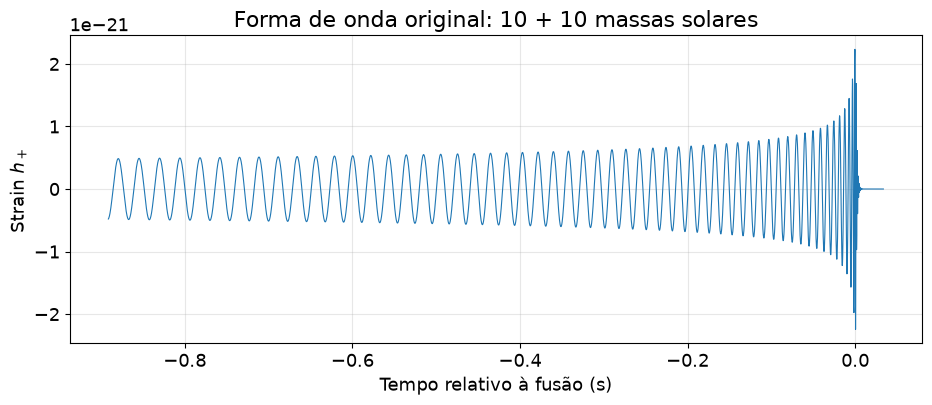

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pycbc.waveform import get_td_waveform

plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 13})

fs = 4096
apx = 'SEOBNRv2'
f_lower = 40
distance = 100

# Sistema original: 10 + 10 massas solares
hp, hc = get_td_waveform(
    approximant=apx,
    mass1=10,
    mass2=10,
    delta_t=1.0/fs,
    distance=distance,
    f_lower=f_lower,
)

time = np.asarray(hp.sample_times)
h = np.asarray(hp)
N = len(hp)
dt = float(hp.delta_t)

print(f"Taxa de amostragem: {1/dt:.0f} Hz")
print(f"Número de amostras: {N}")
print(f"Duração total: {N*dt:.4f} s")

plt.plot(time, h, linewidth=0.8)
plt.xlabel('Tempo relativo à fusão (s)')
plt.ylabel('Strain $h_+$')
plt.title('Forma de onda original: 10 + 10 massas solares')
plt.grid(alpha=0.3)
plt.show()

## Questões de verificação

### 1. No trecho inicial do sinal, qual foi a frequência estimada?

**Resposta:** aproximadamente **40–50 Hz** no primeiro terço da forma de onda. O valor varia gradualmente, pois a frequência aumenta durante a aproximação dos objetos compactos.

Para verificar a estimativa, localizamos máximos sucessivos da senoide e medimos o intervalo $T$ entre eles:

$$
f \simeq \frac{1}{T}.
$$

O código fornece uma estimativa a partir da mediana dos períodos entre picos.

Frequência estimada no trecho inicial: 42.9 Hz


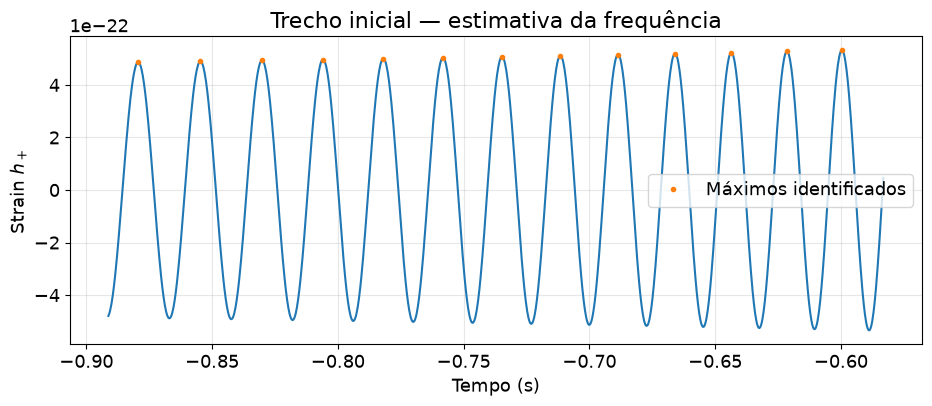

In [2]:
# Trecho inicial: primeiro terço da forma de onda
fim_inicial = N // 3
t_inicial = time[:fim_inicial]
h_inicial = h[:fim_inicial]

picos_iniciais, _ = signal.find_peaks(h_inicial)
periodos_iniciais = np.diff(t_inicial[picos_iniciais])
frequencia_inicial = 1 / np.median(periodos_iniciais)

print(f"Frequência estimada no trecho inicial: {frequencia_inicial:.1f} Hz")

plt.plot(t_inicial, h_inicial)
plt.plot(t_inicial[picos_iniciais], h_inicial[picos_iniciais], '.',
         label='Máximos identificados')
plt.xlabel('Tempo (s)')
plt.ylabel('Strain $h_+$')
plt.title('Trecho inicial — estimativa da frequência')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2. No trecho final, próximo à fusão, qual foi a frequência estimada?

**Resposta:** a frequência não é constante: no intervalo dos últimos $0{,}02$ s antes da fusão ela cresce rapidamente, atingindo **centenas de hertz**. Dependendo do trecho escolhido para medir o período, as estimativas podem ficar aproximadamente entre **150 e 300 Hz**, ou mais próximo da fusão.

A estimativa abaixo considera máximos entre $-0{,}02$ s e $-0{,}001$ s, evitando a parte posterior à fusão (*ringdown*).

Frequência típica no trecho final: 186.2 Hz
Frequências estimadas a partir dos picos: 163.8–256.0 Hz


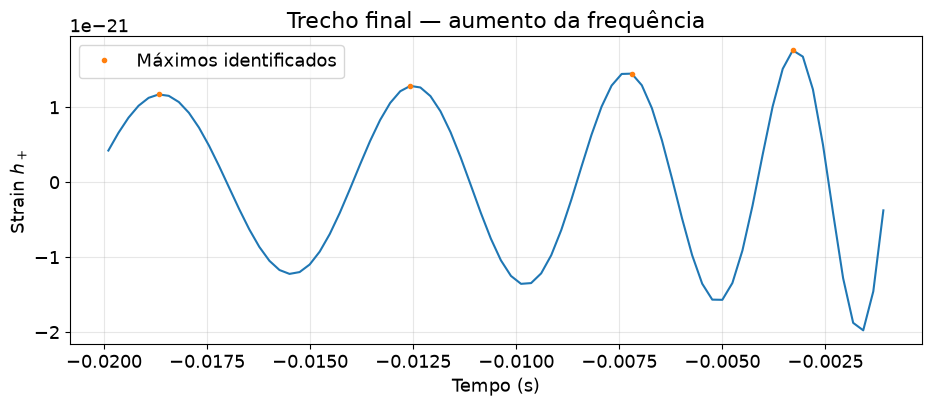

In [3]:
# Trecho próximo à fusão, ainda antes de t = 0
mascara_final = (time >= -0.02) & (time <= -0.001)
t_final = time[mascara_final]
h_final = h[mascara_final]

picos_finais, _ = signal.find_peaks(h_final)
periodos_finais = np.diff(t_final[picos_finais])

if len(periodos_finais) > 0:
    frequencias_por_ciclo = 1 / periodos_finais
    print(f"Frequência típica no trecho final: {np.median(frequencias_por_ciclo):.1f} Hz")
    print(f"Frequências estimadas a partir dos picos: "
          f"{frequencias_por_ciclo.min():.1f}–{frequencias_por_ciclo.max():.1f} Hz")
else:
    print('Não há picos suficientes nesse trecho para estimar os períodos.')

plt.plot(t_final, h_final)
plt.plot(t_final[picos_finais], h_final[picos_finais], '.',
         label='Máximos identificados')
plt.xlabel('Tempo (s)')
plt.ylabel('Strain $h_+$')
plt.title('Trecho final — aumento da frequência')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3. Qual é a duração total da forma de onda?

**Resposta:** aproximadamente **0,9 s** para o sistema original deste exemplo; o valor preciso é calculado na célula de preparação.

Se $N$ é o número de amostras e $f_s$ a frequência de amostragem:

$$
\boxed{\Delta t = \frac{N}{f_s} = N\,\delta t},
$$

em que $\delta t=1/f_s$ é o intervalo entre amostras. Não confunda a duração $N\delta t$ com a diferença entre o primeiro e o último instante armazenados, que é $(N-1)\delta t$.

In [4]:
duracao = len(hp) * float(hp.delta_t)
print(f"N = {len(hp)} amostras")
print(f"Δt = {duracao:.6f} s")
print(f"Primeiro instante: {time[0]:.6f} s")
print(f"Último instante amostrado: {time[-1]:.6f} s")

N = 3789 amostras
Δt = 0.925049 s
Primeiro instante: -0.891232 s
Último instante amostrado: 0.033573 s


### 4. Em qual frequência a magnitude espectral é maior? Por quê?

**Resposta:** a maior magnitude do espectro exibido ocorre **próximo à extremidade de baixas frequências, pouco acima de 40 Hz**. O código identifica o valor correspondente ao máximo no intervalo representado.

O sistema passa mais tempo nas etapas iniciais da aproximação, quando sua frequência é relativamente baixa. Como resultado, o sinal contribui por mais ciclos e por mais tempo nessa região do espectro. À medida que a fusão se aproxima, a frequência sobe rapidamente e o tempo gasto em cada faixa diminui.

**Atenção:** `np.abs(np.fft.rfft(...))` fornece a **magnitude não normalizada da FFT**, e não diretamente uma energia física. Por isso, no gráfico usamos o rótulo *Magnitude da FFT*.

Frequência de maior magnitude no intervalo exibido: 43.24 Hz


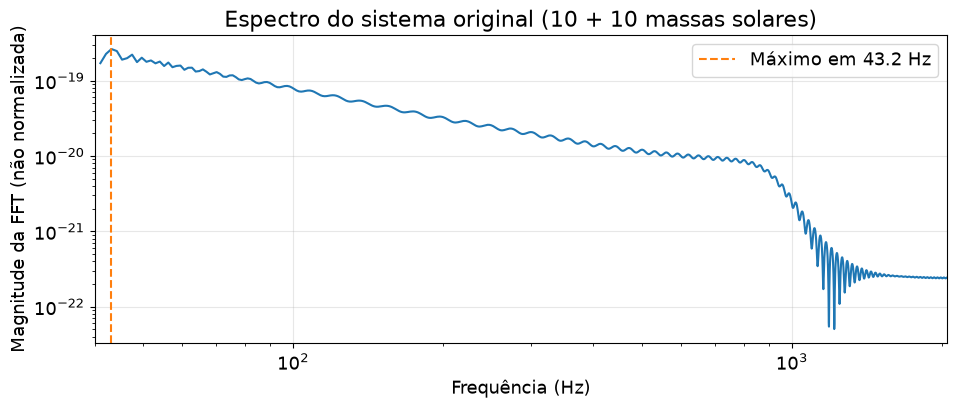

In [5]:
# Espectro sem janela, reproduzindo sua versão simplificada do notebook.
# Se desejar aplicar a janela de Tukey, use: np.fft.rfft(win * h).

def espectro_fft(serie):
    dt_serie = float(serie.delta_t)
    hf = np.fft.rfft(np.asarray(serie))
    f = np.fft.rfftfreq(len(serie), d=dt_serie)
    return f, np.abs(hf)

frequencies, mag_10 = espectro_fft(hp)

# Procurar o pico apenas na faixa mostrada no gráfico original
faixa = (frequencies >= f_lower) & (frequencies <= fs/2)
f_pico = frequencies[faixa][np.argmax(mag_10[faixa])]
print(f"Frequência de maior magnitude no intervalo exibido: {f_pico:.2f} Hz")

plt.loglog(frequencies[faixa], mag_10[faixa])
plt.axvline(f_pico, linestyle='--', color='tab:orange',
            label=f'Máximo em {f_pico:.1f} Hz')
plt.xlim(40, fs/2)
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude da FFT (não normalizada)')
plt.title('Espectro do sistema original (10 + 10 massas solares)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Pratique com Python

### 1. Gerar uma forma de onda com `mass1 = mass2 = 20`

Mantemos o mesmo modelo, a mesma frequência de amostragem, a mesma frequência mínima e a mesma distância usados no sistema original, alterando apenas as massas.

Duração (10 + 10): 0.9250 s
Duração (20 + 20): 0.3140 s


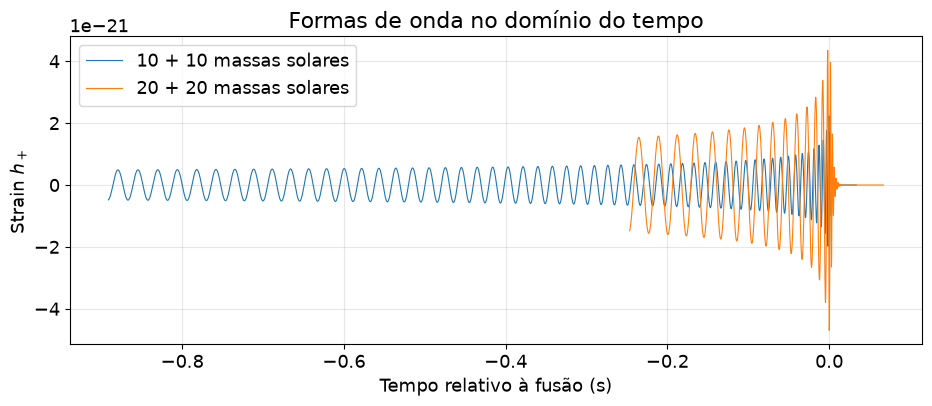

In [6]:
# Novo sistema: 20 + 20 massas solares
hp20, hc20 = get_td_waveform(
    approximant=apx,
    mass1=20,
    mass2=20,
    delta_t=1.0/fs,
    distance=distance,
    f_lower=f_lower,
)

time20 = np.asarray(hp20.sample_times)
print(f"Duração (10 + 10): {len(hp)*float(hp.delta_t):.4f} s")
print(f"Duração (20 + 20): {len(hp20)*float(hp20.delta_t):.4f} s")

plt.plot(time, np.asarray(hp), label='10 + 10 massas solares', linewidth=0.8)
plt.plot(time20, np.asarray(hp20), label='20 + 20 massas solares', linewidth=0.8)
plt.xlabel('Tempo relativo à fusão (s)')
plt.ylabel('Strain $h_+$')
plt.title('Formas de onda no domínio do tempo')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2. Representar os dois espectros no mesmo gráfico

Calculamos a FFT de cada forma de onda com o **mesmo procedimento, sem janela**, como na sua célula simplificada. O número de amostras pode ser diferente para os dois sistemas, portanto cada espectro deve ter seu próprio vetor de frequências.

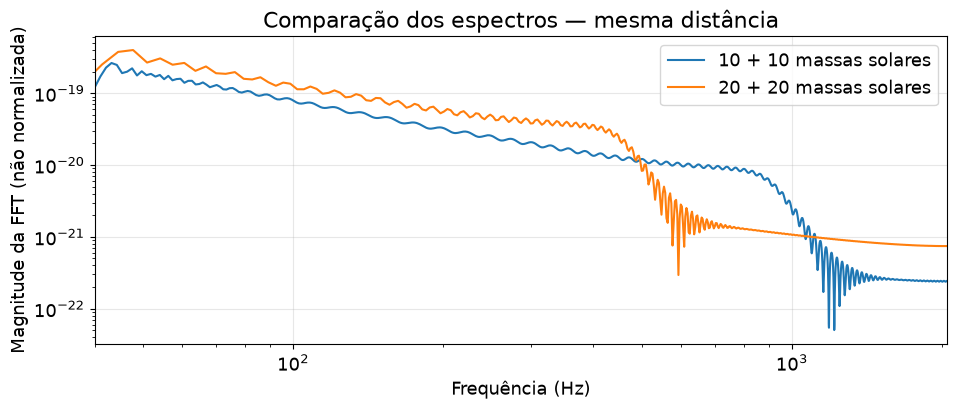

In [7]:
frequencies_10, mag_10 = espectro_fft(hp)
frequencies_20, mag_20 = espectro_fft(hp20)

plt.loglog(frequencies_10[frequencies_10 > 0], mag_10[frequencies_10 > 0],
           label='10 + 10 massas solares')
plt.loglog(frequencies_20[frequencies_20 > 0], mag_20[frequencies_20 > 0],
           label='20 + 20 massas solares')
plt.xlim(40, fs/2)
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude da FFT (não normalizada)')
plt.title('Comparação dos espectros — mesma distância')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 3. Qual sistema apresenta maior frequência de fusão?

**Resposta:** o sistema de **menor massa total (10 + 10 massas solares)** apresenta maior frequência característica próxima da fusão. Sistemas mais massivos atingem a região de fusão com frequências gravitacionais menores.

Como referência aproximada, para sistemas sem rotação, a escala de frequência próxima ao fim da inspiral varia de modo inversamente proporcional à massa total:

$$
f_{\mathrm{caract.}} \propto \frac{1}{M_{\mathrm{total}}}.
$$

Dobrar ambas as massas reduz aproximadamente pela metade essa escala de frequência. Essa relação é uma orientação física, **não** uma leitura exata da frequência de fusão produzida pelo modelo `SEOBNRv2`.

### 4. Qual sistema apresenta maior magnitude espectral em 100 Hz?

**Resposta esperada:** com a **mesma distância** e os demais parâmetros mantidos, o sistema de **20 + 20 massas solares** tende a apresentar maior magnitude espectral em **100 Hz**. Em geral, o aumento da massa de chirp eleva a amplitude da onda nas frequências de inspiral que os dois sistemas compartilham.

Para conferir no resultado da simulação, calculamos as magnitudes em torno de 100 Hz por interpolação linear nos espectros discretos. Pequenas oscilações devido à duração finita dos sinais e à ausência de janela podem afetar os números obtidos.

In [8]:
f_comparacao = 100.0
mag_100_10 = np.interp(f_comparacao, frequencies_10, mag_10)
mag_100_20 = np.interp(f_comparacao, frequencies_20, mag_20)

print(f"Magnitude em 100 Hz (10 + 10): {mag_100_10:.3e}")
print(f"Magnitude em 100 Hz (20 + 20): {mag_100_20:.3e}")
print(f"Razão (20 + 20) / (10 + 10): {mag_100_20 / mag_100_10:.2f}")

if mag_100_20 > mag_100_10:
    print('Maior magnitude em 100 Hz: sistema de 20 + 20 massas solares.')
else:
    print('Neste cálculo, a magnitude foi maior para 10 + 10;')
    print('verifique os efeitos da janela e a resolução espectral.')

Magnitude em 100 Hz (10 + 10): 7.935e-20
Magnitude em 100 Hz (20 + 20): 1.268e-19
Razão (20 + 20) / (10 + 10): 1.60
Maior magnitude em 100 Hz: sistema de 20 + 20 massas solares.


## Nota sobre a janela de Tukey

Na célula simplificada que você adotou, as linhas

```python
win = signal.windows.tukey(len(hp))
hp_win = win * hp
hp_freq = np.fft.rfft(hp)
```

**não aplicam a janela à FFT**: `hp_win` é criado, mas não é usado no cálculo. Para uma FFT sem janela (como a usada neste gabarito), basta `np.fft.rfft(hp)` e as duas primeiras linhas podem ser removidas.

Se quiser utilizar a janela, substitua a última linha por:

```python
hp_freq = np.fft.rfft(hp_win)
```

Para comparar dois espectros, é importante empregar **o mesmo tratamento** em ambos. A aplicação da janela reduz o vazamento espectral, mas modifica as magnitudes, em especial nas partes próximas às extremidades da série temporal.

---
*Material de apoio didático baseado no notebook original `intro-3-waveform.ipynb`. Os créditos e as condições de licença do material de origem devem ser mantidos.*